# Lab Assessment 5: Multivariate Analysis
 | BCSE331P - Exploratory Data Analysis | Fall Semester 2026-27

Dataset: **BEPS**. ggplot2 -> `seaborn`/`matplotlib`; `pairs()` -> `sns.pairplot`; parallel coordinates -> `pandas.plotting`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 1. Load the dataset and identify numerical / categorical variables

In [2]:
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/BEPS.csv"
df = pd.read_csv(URL)

# BEPS has an unnamed row-index column -> drop it; replace '.' in names with '_' (easier in Python)
df = df.loc[:, ~df.columns.str.match(r"^(Unnamed.*|X|rownames)$")]
df.columns = df.columns.str.replace(".", "_", regex=False)
print("Shape:", df.shape)
df.head()

Shape: (1525, 10)


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
0,Liberal Democrat,43,3,3,4,1,4,2,2,female
1,Labour,36,4,4,4,4,4,5,2,male
2,Labour,35,4,4,5,2,3,3,2,male
3,Labour,24,4,2,2,1,3,4,0,female
4,Labour,41,2,2,1,1,4,6,2,male


In [3]:
df = df.dropna().reset_index(drop=True)
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.columns.difference(num_cols).tolist()
print("Numerical variables  :", num_cols)
print("Categorical variables:", cat_cols)
df.dtypes

Numerical variables  : ['age', 'economic_cond_national', 'economic_cond_household', 'Blair', 'Hague', 'Kennedy', 'Europe', 'political_knowledge']
Categorical variables: ['gender', 'vote']


,0
vote,object
age,int64
economic_cond_national,int64
economic_cond_household,int64
Blair,int64
Hague,int64
Kennedy,int64
Europe,int64
political_knowledge,int64
gender,object


## 2. Scatter plot with three variables (x = `age`, y = `Europe`, colour = `vote`)


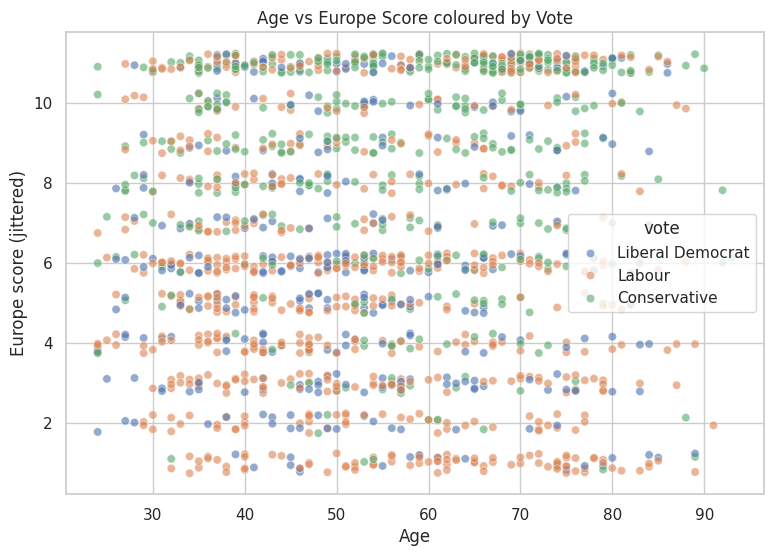

In [4]:
rng = np.random.default_rng(5)
dfj = df.copy()
dfj["Europe_j"] = dfj["Europe"] + rng.uniform(-0.25, 0.25, len(dfj))

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=dfj, x="age", y="Europe_j", hue="vote", alpha=0.6, ax=ax)
ax.set_title("Age vs Europe Score coloured by Vote")
ax.set_xlabel("Age")
ax.set_ylabel("Europe score (jittered)")
plt.show()

## 3. Four variables - colour = `vote`, shape = `gender`

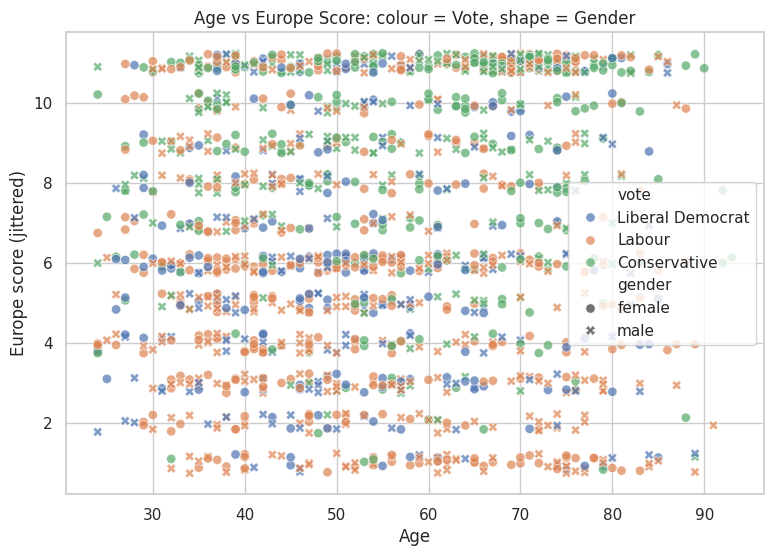

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=dfj, x="age", y="Europe_j", hue="vote", style="gender", alpha=0.7, s=45, ax=ax)
ax.set_title("Age vs Europe Score: colour = Vote, shape = Gender")
ax.set_xlabel("Age")
ax.set_ylabel("Europe score (jittered)")
plt.show()

## 4. Four variables - colour = `vote`, point size = `Blair` (numerical)

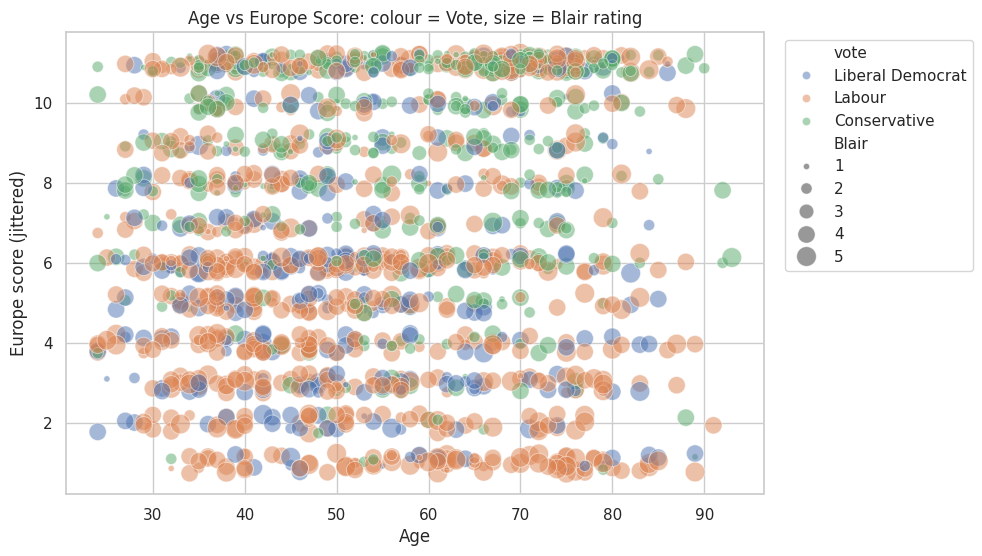

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=dfj, x="age", y="Europe_j", hue="vote", size="Blair", sizes=(20, 200),
                alpha=0.5, ax=ax)
ax.set_title("Age vs Europe Score: colour = Vote, size = Blair rating")
ax.set_xlabel("Age")
ax.set_ylabel("Europe score (jittered)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## 5. Bubble plot (x = `age`, y = `Europe`, bubble size = `Blair`)


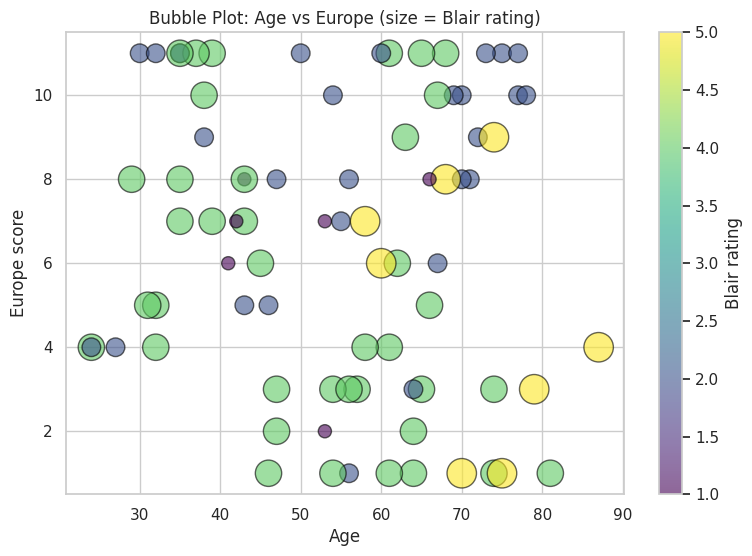

In [7]:
samp = df.sample(80, random_state=3)
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(samp["age"], samp["Europe"], s=samp["Blair"] * 90, c=samp["Blair"], cmap="viridis",
                alpha=0.6, edgecolor="black")
plt.colorbar(sc, ax=ax, label="Blair rating")
ax.set_title("Bubble Plot: Age vs Europe (size = Blair rating)")
ax.set_xlabel("Age")
ax.set_ylabel("Europe score")
plt.show()

## 6. `facet_wrap()` - one panel per `vote`

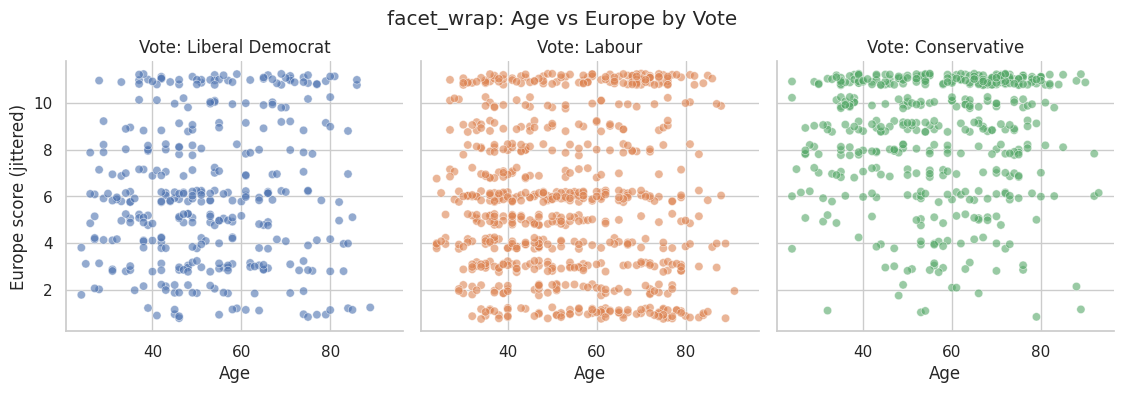

In [8]:
g = sns.relplot(data=dfj, x="age", y="Europe_j", col="vote", col_wrap=3, hue="vote",
                height=3.8, alpha=0.6, legend=False)
g.set_titles("Vote: {col_name}")
g.set_axis_labels("Age", "Europe score (jittered)")
g.figure.suptitle("facet_wrap: Age vs Europe by Vote", y=1.03)
plt.show()

## 7. `facet_grid()` - rows = `gender`, columns = `vote`

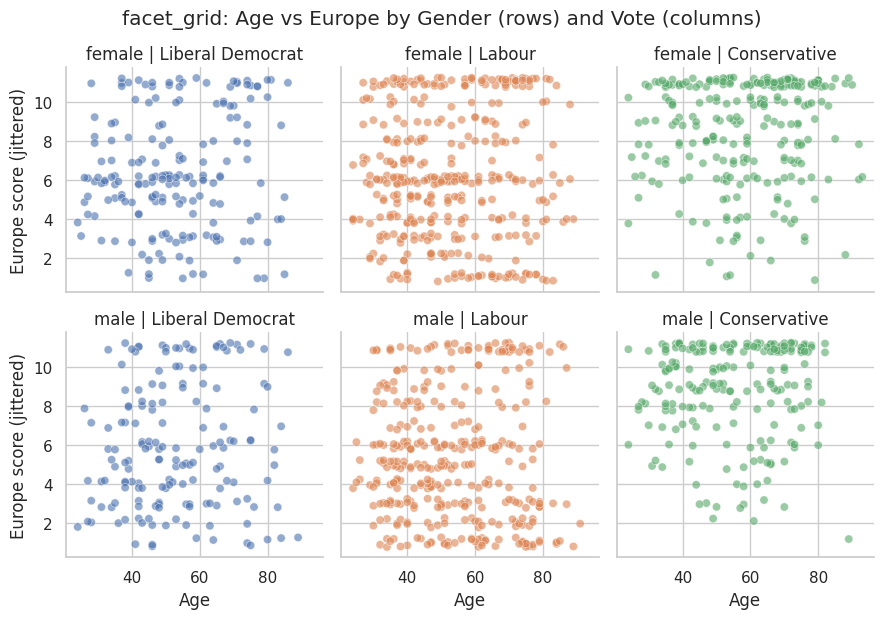

                           age  Europe
gender vote                           
female Conservative      58.29    8.56
       Labour            52.54    6.15
       Liberal Democrat  52.97    6.36
male   Conservative      55.05    8.78
       Labour            53.50    5.35
       Liberal Democrat  53.10    5.91


In [9]:
g = sns.relplot(data=dfj, x="age", y="Europe_j", row="gender", col="vote", hue="vote",
                height=3, alpha=0.6, legend=False)
g.set_titles("{row_name} | {col_name}")
g.set_axis_labels("Age", "Europe score (jittered)")
g.figure.suptitle("facet_grid: Age vs Europe by Gender (rows) and Vote (columns)", y=1.03)
plt.show()

print(df.groupby(["gender", "vote"])[["age", "Europe"]].mean().round(2))

**Observation:** compare the cloud position (average Europe score / age) across the panels using the table above and describe the pattern in each group.

## 8. Pairs plot (5 numerical variables)

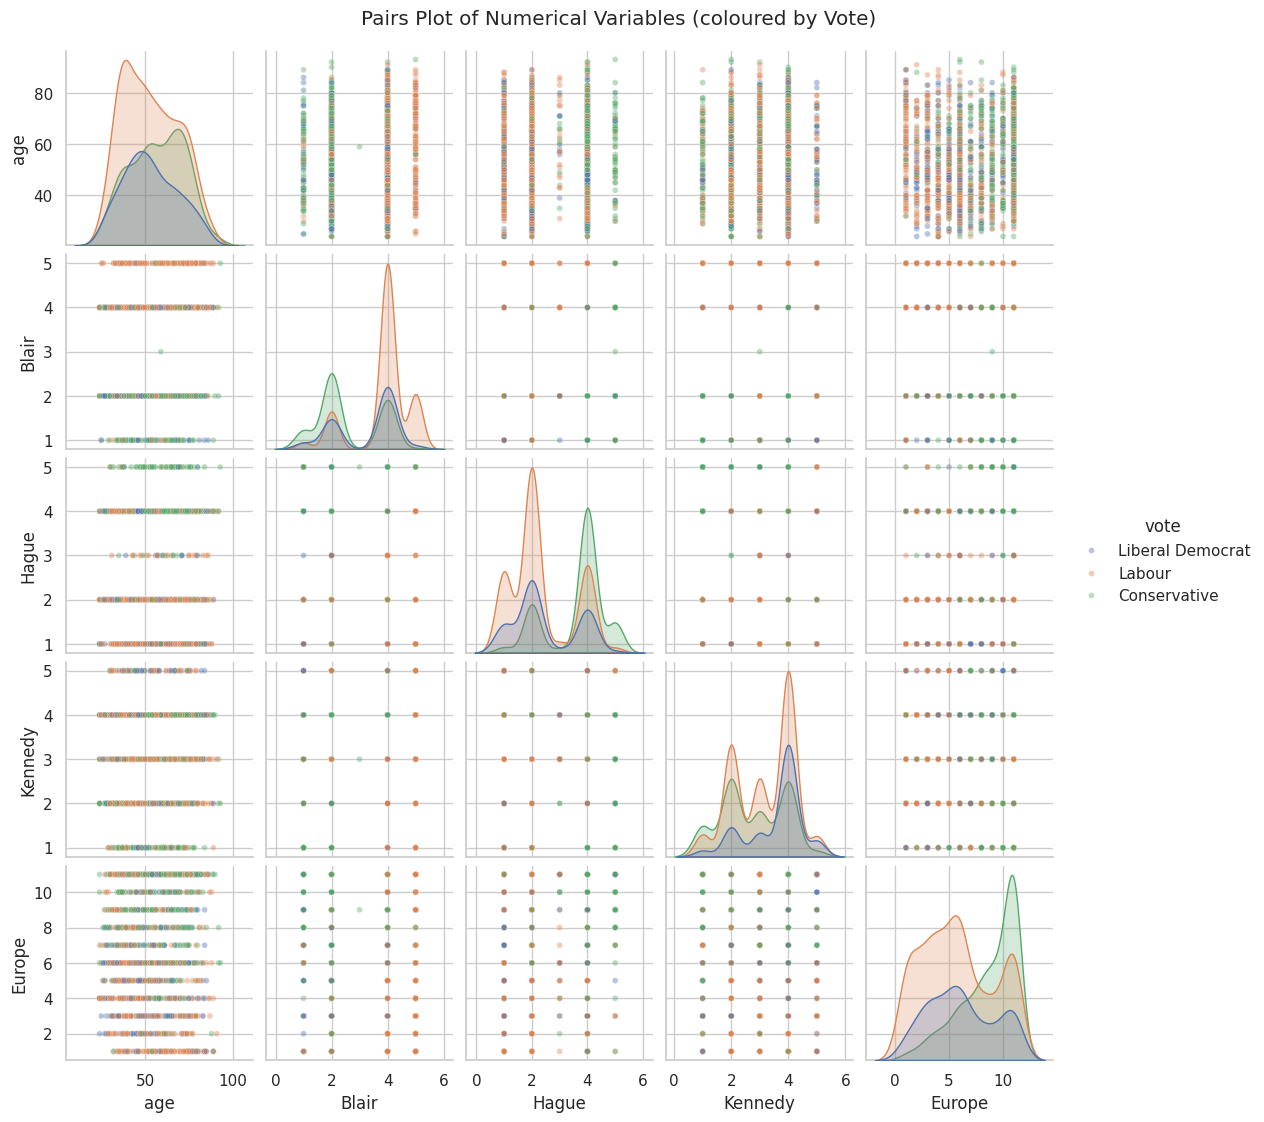

Correlation matrix of selected variables:


,age,Blair,Hague,Kennedy,Europe
age,1.00,0.03,0.03,0.00,0.07
Blair,0.03,1.00,-0.24,0.15,-0.30
Hague,0.03,-0.24,1.00,-0.08,0.29
Kennedy,0.00,0.15,-0.08,1.00,-0.11
Europe,0.07,-0.30,0.29,-0.11,1.00


In [10]:
pair_cols = ["age", "Blair", "Hague", "Kennedy", "Europe"]
g = sns.pairplot(df[pair_cols + ["vote"]], hue="vote", corner=False, diag_kind="kde",
                 plot_kws={"alpha": 0.4, "s": 18}, height=2.2)
g.figure.suptitle("Pairs Plot of Numerical Variables (coloured by Vote)", y=1.02)
plt.show()

print("Correlation matrix of selected variables:")
display(df[pair_cols].corr().round(2))

## 9. Parallel coordinate plot (min-max scaled, coloured by `vote`)

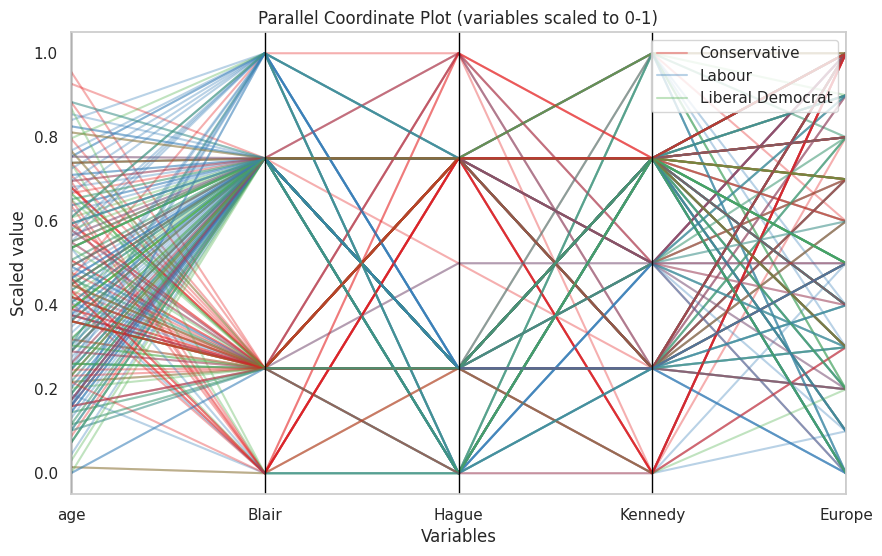

In [11]:
from pandas.plotting import parallel_coordinates

pc_cols = ["age", "Blair", "Hague", "Kennedy", "Europe"]
pc = df[pc_cols + ["vote"]].copy()
pc[pc_cols] = (pc[pc_cols] - pc[pc_cols].min()) / (pc[pc_cols].max() - pc[pc_cols].min())
pc = pc.sample(250, random_state=1)

fig, ax = plt.subplots(figsize=(10, 6))
parallel_coordinates(pc, "vote", color=sns.color_palette("Set1", pc["vote"].nunique()), alpha=0.35, ax=ax)
ax.set_title("Parallel Coordinate Plot (variables scaled to 0-1)")
ax.set_xlabel("Variables")
ax.set_ylabel("Scaled value")
plt.show()